# IADS5 · TP integrador — Ortelana Textil
### Actividad 03 · Primer modelo estadístico

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 03 · Primer modelo estadístico

**Qué se espera:** Entrená LogisticRegression para clasificación y LinearRegression para regresión con las variables numéricas adecuadas; compará con sus baselines. Analizá coeficientes y una matriz de confusión o gráfico real vs. predicho.

**Evidencia a entregar:** Métricas comparativas, coeficientes y visualización.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

# Regresión de Metros2: mismas filas de train y test
features_reg = ["Sucursal_ID", "Tela_ID", "Año", "Metros1"]
Xr_train, Xr_test = train[features_reg], test[features_reg]
yr_train, yr_test = train["Metros2"], test["Metros2"]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
# 3.1 Regresión logística multinomial con las variables numéricas (escaladas)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

num_cols = ["Año", "Metros1", "Metros2"]   # Sucursal_ID es un código, no una cantidad: no entra acá

logit = Pipeline([("escalar", StandardScaler()),
                  ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
logit.fit(X_train[num_cols], y_train)
pred_logit = logit.predict(X_test[num_cols])
pred_base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)

comparacion = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, pred_base), accuracy_score(y_test, pred_logit)],
    "F1 macro": [f1_score(y_test, pred_base, average="macro"), f1_score(y_test, pred_logit, average="macro")],
}, index=["Baseline", "Regresión logística"])
display(comparacion.round(4))

print(classification_report(y_test, pred_logit, digits=4))

,Accuracy,F1 macro
Baseline,0.2831,0.1103
Regresión logística,0.7336,0.7296


              precision    recall  f1-score   support

           B     0.5850    0.5890    0.5870       146
           C     0.8816    0.7791    0.8272       172
           M     0.6502    0.8627    0.7416       153
           S     0.8387    0.6989    0.7625       186

    accuracy                         0.7336       657
   macro avg     0.7389    0.7324    0.7296       657
weighted avg     0.7497    0.7336    0.7356       657



,Año,Metros1,Metros2
B,-0.0532,-3.3228,2.3272
C,0.0794,2.7413,-0.1084
M,-0.1399,0.2381,-4.7482
S,0.1136,0.3435,2.5293


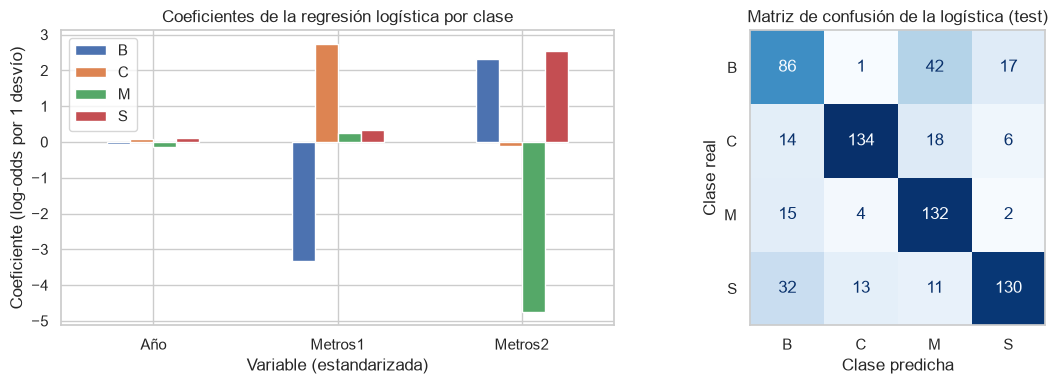

In [3]:
# 3.2 Coeficientes (variables estandarizadas: cambio en el log-odds de cada clase por +1 desvío)
from sklearn.metrics import ConfusionMatrixDisplay

coef = pd.DataFrame(logit.named_steps["modelo"].coef_, index=logit.classes_, columns=num_cols)
display(coef.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coef.T.plot(kind="bar", rot=0, ax=axes[0])
axes[0].set(title="Coeficientes de la regresión logística por clase",
            xlabel="Variable (estandarizada)", ylabel="Coeficiente (log-odds por 1 desvío)")

ConfusionMatrixDisplay.from_predictions(y_test, pred_logit, ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set(title="Matriz de confusión de la logística (test)", xlabel="Clase predicha", ylabel="Clase real")
axes[1].grid(False)
plt.tight_layout()
plt.show()

In [4]:
# 3.3 Regresión lineal de Metros2 con las variables numéricas (Año, Metros1)
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metricas_reg(y_real, y_pred):
    """MAE, MSE, RMSE y R² en metros."""
    mse = mean_squared_error(y_real, y_pred)
    return {"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_real, y_pred)}

num_reg = ["Año", "Metros1"]
lineal = LinearRegression().fit(Xr_train[num_reg], yr_train)
pred_lineal = lineal.predict(Xr_test[num_reg])
pred_media = DummyRegressor(strategy="mean").fit(Xr_train, yr_train).predict(Xr_test)

display(pd.DataFrame([metricas_reg(yr_test, pred_media), metricas_reg(yr_test, pred_lineal)],
                     index=["Baseline (media)", "Regresión lineal"]).round(4))

print("Intercepto:", round(lineal.intercept_, 2))
pd.Series(lineal.coef_, index=num_reg, name="coeficiente (metros por unidad)").round(4)

,MAE,MSE,RMSE,R2
Baseline (media),695.9745,853337.7914,923.7628,-0.0036
Regresión lineal,231.9628,152355.5113,390.3274,0.8208


Intercepto: 11677.77


Año       -5.7037
Metros1    0.8426
Name: coeficiente (metros por unidad), dtype: float64

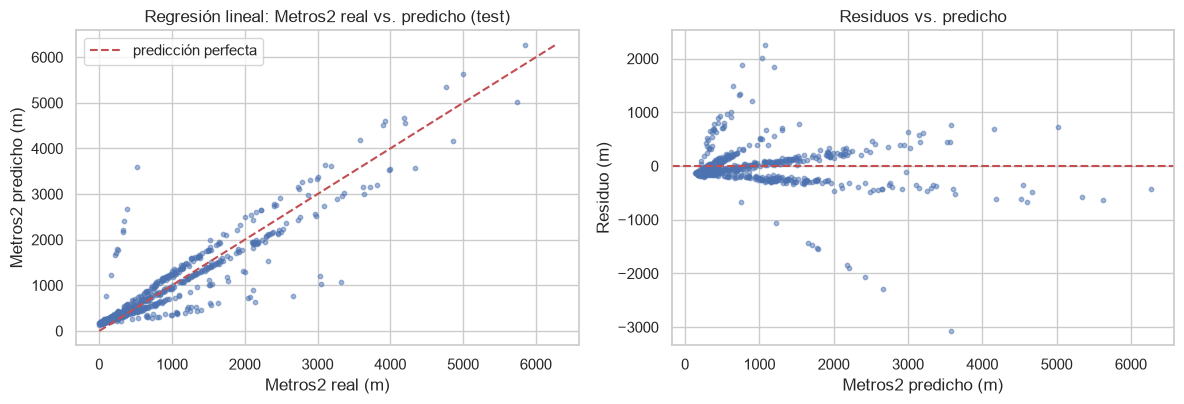

In [5]:
# 3.4 Real vs. predicho y residuos
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].scatter(yr_test, pred_lineal, s=10, alpha=0.5)
limite = max(yr_test.max(), pred_lineal.max())
axes[0].plot([0, limite], [0, limite], "r--", label="predicción perfecta")
axes[0].set(title="Regresión lineal: Metros2 real vs. predicho (test)",
            xlabel="Metros2 real (m)", ylabel="Metros2 predicho (m)")
axes[0].legend()

axes[1].scatter(pred_lineal, yr_test - pred_lineal, s=10, alpha=0.5)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(title="Residuos vs. predicho", xlabel="Metros2 predicho (m)", ylabel="Residuo (m)")

plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Clasificación:** `LogisticRegression` multinomial con las variables numéricas adecuadas (`Año`, `Metros1`, `Metros2`), escaladas con `StandardScaler` dentro de un `Pipeline`.
  - El escalado hace que los coeficientes sean comparables, porque quedan expresados por cada desvío estándar.
  - `Sucursal_ID` no entra como número: es un código, y tratarlo como cantidad sería inventar un orden.
- **Regresión:** `LinearRegression` de `Metros2` con `Año` y `Metros1`.
- **Visualizaciones:** coeficientes, matriz de confusión y gráfico real vs. predicho con residuos.

**Interpretación de los resultados:**
- **Logística:** sube de F1 macro 0,110 a **0,730** (accuracy 0,734).
  - Las clases mejor separadas son C (F1 0,83) y S (0,76).
  - B es la más difícil (0,59), porque su volumen queda entre M y C/S.
  - En la matriz de confusión, los errores se concentran entre B y M, y entre C y S.
- **Coeficientes:**
  - Un `Metros2` alto baja mucho la probabilidad de M (−4,75) y sube la de S (+2,53) y B (+2,33).
  - Un `Metros1` alto sube C (+2,74) y baja B (−3,32).
  - `Año` tiene coeficientes cercanos a 0.
  - El modelo separa por volumen, y también por la relación entre el primer y el segundo período.
  - **En términos de odds (Unidad 2):** cada coeficiente multiplica las odds de la clase por e^β por cada desvío estándar de la variable. Por ejemplo, +1 desvío de `Metros2` multiplica las odds de M por e^−4,75 ≈ 0,009 (las reduce casi a cero) y las de S por e^2,53 ≈ 12,6; +1 desvío de `Metros1` multiplica las odds de C por e^2,74 ≈ 15,5.
- **Regresión lineal:**
  - Pasa de RMSE 924 m a **390 m**, con R² = 0,821 y MAE = 232 m.
  - Por cada metro de `Metros1`, `Metros2` aumenta en promedio 0,84 m, y el año aporta −5,7 m por año.
  - Los residuos crecen con el valor predicho (heterocedasticidad): el error es mayor en los registros grandes.

**Pregunta de análisis:** ¿Qué coeficientes son relevantes y por qué? ¿Puede interpretarse un coeficiente como causalidad?
- **Relevantes:**
  - En la logística, los de `Metros1` y `Metros2`: tienen la mayor magnitud con las variables estandarizadas (|coef| medio de 1,66 y 2,43, frente a 0,10 de `Año`).
  - En la regresión, el de `Metros1` (0,84 m/m), porque el volumen de un período anticipa el del siguiente.
- **Causalidad:** no. Un coeficiente mide una asociación condicional en estos datos observacionales. Que M tenga coeficiente negativo en `Metros2` no significa que vender menos "cause" el formato M. Es al revés: el formato define la duración del período, y eso determina cuántos metros caen en él. Además, `Metros1` y `Metros2` están muy correlacionados (0,906), lo que vuelve inestable el reparto de efectos entre ellos.

**Limitaciones o mejoras posibles:**
- Ninguno de los dos modelos usa la sucursal ni la tela.
- La relación con el volumen no es lineal ni homocedástica: una transformación log o modelos no lineales podrían mejorar el resultado.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
